# SI Fig. S3: barcode frequency stability across timepoints, Expt 3

One row per population -- the unexposed control and the two UV-exposed replicates --
showing barcode frequency at each timepoint against the next, as in SI Figs. S1g and
S2.

Counts are multiplied by the filter mask rather than sliced, so lineages failing the
t0 cutoff contribute zeros and each timepoint is normalised by the surviving total.

Runtime: ~30 s.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import sys, time

import numpy as np
import matplotlib.pyplot as plt

from barfly import expt3 as e3                              # noqa: E402
from barfly.plotting import use_paper_style                 # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
use_paper_style()
t_start = time.time()

PANEL = {"20260224_yKH88": "figS03b",
         "20260224_yKH88UV_A": "figS03c",
         "20260224_yKH88UV_B": "figS03d"}

full = e3.load_timecourse()

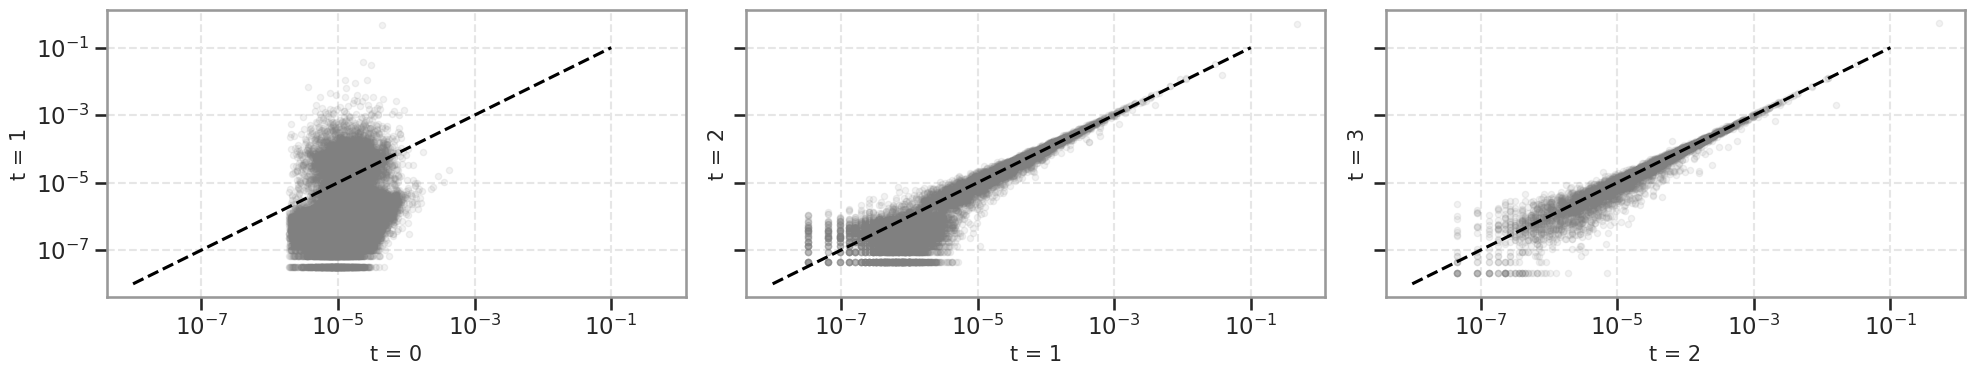

20260224_yKH88: 349909 barcodes, 78968 pass the t0 cutoff


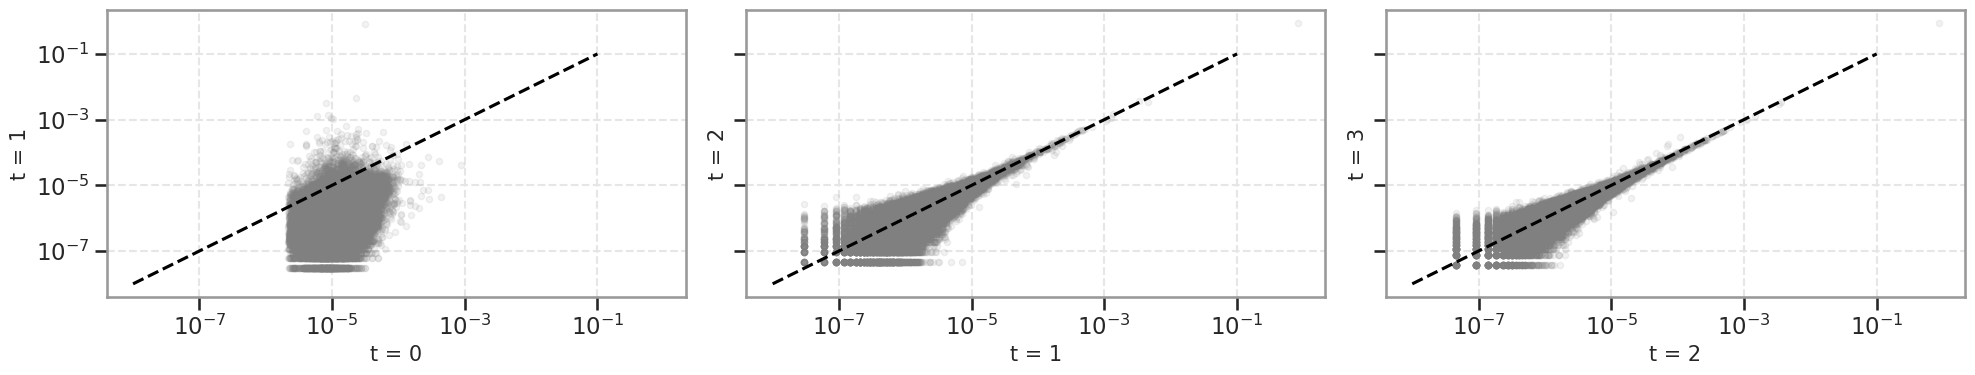

20260224_yKH88UV_A: 433486 barcodes, 79919 pass the t0 cutoff


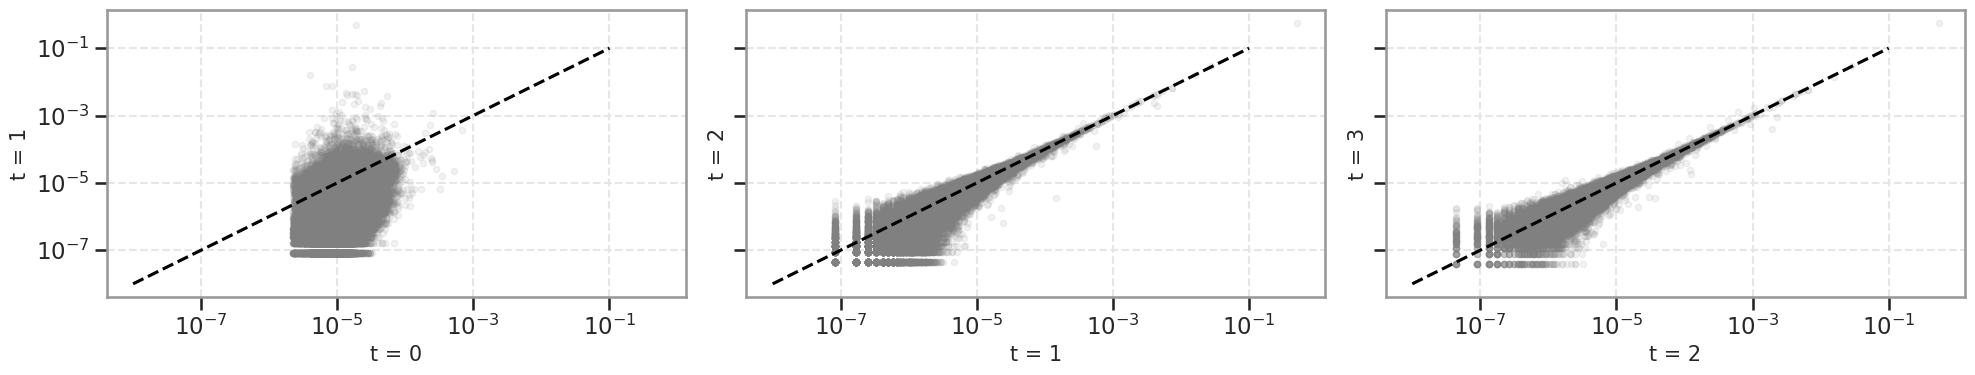

20260224_yKH88UV_B: 143567 barcodes, 78403 pass the t0 cutoff
Done in 4.4s.


In [2]:
sys.path.insert(0, str(ROOT))
from barfly import expt3 as e3                              # noqa: E402
from barfly.plotting import use_paper_style                 # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
use_paper_style()
t_start = time.time()

PANEL = {"20260224_yKH88": "figS03b",
         "20260224_yKH88UV_A": "figS03c",
         "20260224_yKH88UV_B": "figS03d"}

full = e3.load_timecourse()
for key, (counts, mask) in full.items():
    masked = counts * mask
    fig, axs = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(20, 4))
    for t in np.arange(3):
        axs[t].plot(masked[t, :] / np.sum(masked[t, :]),
                    masked[t + 1, :] / np.sum(masked[t + 1, :]),
                    ".", color="gray", rasterized=True, alpha=0.1)
        axs[t].set_xscale("log"); axs[t].set_yscale("log")
        axs[t].set_xlabel(f"t = {t}"); axs[t].set_ylabel(f"t = {t+1}")
        axs[t].plot([1e-8, 1e-1], [1e-8, 1e-1], '--k')
    plt.tight_layout()
    short = key.replace("20260224_", "")
    plt.savefig(OUT / f"{PANEL[key]}_trajectories_{short}.svg",
                bbox_inches="tight", dpi=300)
    plt.show()
    print(f"{key}: {counts.shape[1]} barcodes, {int(mask.sum())} pass the t0 cutoff")

print(f"Done in {time.time()-t_start:.1f}s.")